# Analysis of County-Level Health Indicators and Population Differences

## Introduction

### In this project, I analyse health indicators across counties and population groups using the 2021 Community Health Status Profile dataset. The dataset contains information about health outcomes, counties, demographic groups, rates, denominators, confidence limits, and Healthy People objectives. I follow a structured approach that begins with loading and understanding the data, continues with cleaning and preprocessing, and then uses exploratory data analysis (EDA), visualizations, and insight generation to examine patterns and differences.

##### Before starting the analysis, I import the Python libraries needed to work with the dataset and create visualizations:

- Pandas is used to load and manipulate tabular data.
- NumPy is used for numerical operations.
- Matplotlib and Seaborn are used to create charts and visualizations.

#### Problem statement

The purpose of this analysis is to explore how selected health indicators vary across counties and population groups. I examine county differences, compare demographic groups where data is available, and review whether reported results meet Healthy People objectives.

#### Objectives

1. to understand the structure and quality of the dataset.
2. to check for missing values, duplicate records, and data type issues.
3. to compare county rates for selected health indicators.
4. to explore differences across age, sex, and race/ethnicity groups where comparable data is available.
5. to summarize Healthy People objective status.
6. to present findings with statistical summaries and visualizations.
7. to explain limitations that affect interpretation, including differing reporting periods and confidence intervals.

#### IMPORTING THE LIBRARIES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### LOADING THE DATA SET

##### this code loads the data set and displays first 5 rows 

In [4]:
df = pd.read_csv("chsp_2021_odp_2021-04-08.csv")
df.head()

,Publication_Year,Table,Health_Indicator_Desc,Strata,Strata_Name,County,Rank_Order,Denominator_Total,Denominator_Average,Denominator_Label,...,Lower_Confidence_Limit,Upper_Confidence_Limit,Healthy_People_Decade,Healthy_People_Objective_Number,Healthy_People_Objective_Target,Healthy_People_Objective_Met,Denominator_Annotation_Code,Numerator_Annotation_Code,Rates_Annotation_Code,Annotation_Desc
0,2021,1,Deaths Due to All Causes,Total Population,Total Population,Mono,1.0,13827.0,13827.0,Population,...,291.6,405.1,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021,1,Deaths Due to All Causes,Total Population,Total Population,San Mateo,2.0,774570.0,774570.0,Population,...,418.7,433.5,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021,1,Deaths Due to All Causes,Total Population,Total Population,Santa Clara,3.0,1955946.0,1955946.0,Population,...,455.3,465.7,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021,1,Deaths Due to All Causes,Total Population,Total Population,Marin,4.0,262326.0,262326.0,Population,...,449.2,473.7,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021,1,Deaths Due to All Causes,Total Population,Total Population,San Francisco,5.0,886618.0,886618.0,Population,...,473.6,488.2,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### INSPECTING THE DATA SET

##### this code shows the no. of rows and columns in the data set

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2183
Number of columns: 30


#### COLUMNS
##### this code diplays all the column names

In [6]:
print(df.columns)

Index(['Publication_Year', 'Table', 'Health_Indicator_Desc', 'Strata',
       'Strata_Name', 'County', 'Rank_Order', 'Denominator_Total',
       'Denominator_Average', 'Denominator_Label', 'Denominator_Year_Period',
       'Numerator_Total', 'Numerator_Average', 'Numerator_Label',
       'Numerator_Year_Period', 'Rate_Multiplier', 'Rate/Percentage',
       'Rate/Percentage_Label', 'Age-Adjusted_Rate', 'Age-Adjusted_Rate_Label',
       'Lower_Confidence_Limit', 'Upper_Confidence_Limit',
       'Healthy_People_Decade', 'Healthy_People_Objective_Number',
       'Healthy_People_Objective_Target', 'Healthy_People_Objective_Met',
       'Denominator_Annotation_Code', 'Numerator_Annotation_Code',
       'Rates_Annotation_Code', 'Annotation_Desc'],
      dtype='str')


#### THE DATATYPES OF THE COLUMNS
##### this code displays the column names and its datatype

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2183 entries, 0 to 2182
Data columns (total 30 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Publication_Year                 2183 non-null   int64  
 1   Table                            2183 non-null   str    
 2   Health_Indicator_Desc            2183 non-null   str    
 3   Strata                           2183 non-null   str    
 4   Strata_Name                      2183 non-null   str    
 5   County                           2183 non-null   str    
 6   Rank_Order                       1966 non-null   float64
 7   Denominator_Total                2161 non-null   float64
 8   Denominator_Average              2161 non-null   float64
 9   Denominator_Label                2183 non-null   str    
 10  Denominator_Year_Period          2183 non-null   str    
 11  Numerator_Total                  2010 non-null   float64
 12  Numerator_Average              

#### This code provides count, mean, standard deviation, minimum, maximum and quartile values for numeric columns.These statistics help me understand the numerical ranges in the dataset

In [8]:
df.describe()

,Publication_Year,Rank_Order,Denominator_Total,Denominator_Average,Numerator_Total,Numerator_Average,Rate_Multiplier,Rate/Percentage,Age-Adjusted_Rate,Lower_Confidence_Limit,Upper_Confidence_Limit,Healthy_People_Decade,Healthy_People_Objective_Target,Denominator_Annotation_Code,Numerator_Annotation_Code,Rates_Annotation_Code
count,2183.0,1966.000000,2.161000e+03,2.161000e+03,2.010000e+03,2.010000e+03,2183.000000,1883.00000,1112.000000,1883.000000,1883.000000,2183.0,1652.000000,22.0,173.0,544.000000
mean,2021.0,27.775687,8.369592e+05,8.319246e+05,6.671715e+03,3.245218e+03,73145.945946,97.71880,66.108094,78.914392,97.852151,2020.0,41.660714,1.0,1.0,2.812500
std,0.0,16.306449,4.010290e+06,4.010777e+06,5.789018e+04,3.910668e+04,44136.419122,194.66771,151.233020,160.492715,179.312609,0.0,62.790847,0.0,0.0,1.299437
min,2021.0,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,100.000000,0.20000,1.400000,0.000000,1.400000,2020.0,1.000000,1.0,1.0,1.000000
25%,2021.0,14.000000,1.137200e+04,7.428000e+03,3.500000e+01,1.170000e+01,1000.000000,12.10000,13.300000,7.850000,14.100000,2020.0,6.000000,1.0,1.0,1.000000
50%,2021.0,27.000000,6.470300e+04,6.143700e+04,1.675000e+02,5.615000e+01,100000.000000,25.40000,21.200000,16.900000,28.400000,2020.0,10.750000,1.0,1.0,3.000000
75%,2021.0,41.000000,3.892780e+05,3.818540e+05,9.607500e+02,3.320000e+02,100000.000000,78.55000,39.850000,68.350000,81.700000,2020.0,38.675000,1.0,1.0,4.000000
max,2021.0,58.000000,3.981778e+07,3.981778e+07,1.539628e+06,1.539628e+06,100000.000000,1915.10000,1332.800000,1880.800000,1949.300000,2020.0,251.900000,1.0,1.0,4.000000


##### Creating a copy of the working data set for analysis called cdata

In [9]:
cdata = df.copy()

##### Checking for missing values

In [12]:
cdata.isnull().sum().sort_values(ascending=False)

Denominator_Annotation_Code        2161
Numerator_Annotation_Code          2010
Annotation_Desc                    1639
Rates_Annotation_Code              1639
Age-Adjusted_Rate                  1071
Age-Adjusted_Rate_Label            1062
Healthy_People_Objective_Met        538
Healthy_People_Objective_Target     531
Healthy_People_Objective_Number     472
Rate/Percentage                     300
Upper_Confidence_Limit              300
Lower_Confidence_Limit              300
Rank_Order                          217
Numerator_Total                     173
Numerator_Average                   173
Denominator_Total                    22
Denominator_Average                  22
Numerator_Label                       0
Health_Indicator_Desc                 0
Strata                                0
Strata_Name                           0
County                                0
Publication_Year                      0
Denominator_Year_Period               0
Denominator_Label                     0


##### Handling the missing text values by repalcing it with "Not Available"

In [18]:
text_cols = [
    'Denominator_Annotation_Code',
    'Numerator_Annotation_Code',
    'Rates_Annotation_Code',
    'Annotation_Desc'
]

for column in text_cols:
    cdata[column] = cdata[column].fillna('Not Available')

In [20]:
cdata[text_cols].isnull().sum()

Denominator_Annotation_Code    0
Numerator_Annotation_Code      0
Rates_Annotation_Code          0
Annotation_Desc                0
dtype: int64

##### Handling the missing numeric values by replacing it with median

In [29]:
numeric_cols = cdata.select_dtypes(include='number').columns
for column in numeric_cols:
    cdata[column] = cdata[column].fillna(cdata[column].median())

In [30]:
cdata[numeric_cols].isnull().sum()

Publication_Year                   0
Rank_Order                         0
Denominator_Total                  0
Denominator_Average                0
Numerator_Total                    0
Numerator_Average                  0
Rate_Multiplier                    0
Rate/Percentage                    0
Age-Adjusted_Rate                  0
Lower_Confidence_Limit             0
Upper_Confidence_Limit             0
Healthy_People_Decade              0
Healthy_People_Objective_Target    0
dtype: int64

##### Checking for duplicate values

In [31]:
print("Number of duplicate rows:", cdata.duplicated().sum())

Number of duplicate rows: 0


#### Exploratory Data Analysis

##### In this section, I explore health rates across California counties. I use charts to examine the distribution of rates, compare counties, and review Healthy People objective status. Missing rates are left out of rate charts because they are not reported values.

#### Diabetes Death Rates by County

I selected diabetes deaths as an example health indicator. The histogram and box plot show how rates vary across counties. The bar charts identify counties with the highest and lowest reported rates.

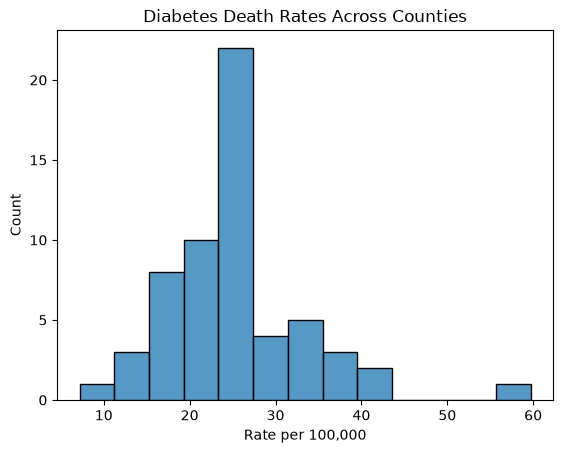

In [46]:
# 1. Histogra
sns.histplot(diabetes["Rate/Percentage"])
plt.title("Diabetes Death Rates Across Counties")
plt.xlabel("Rate per 100,000")
plt.show()

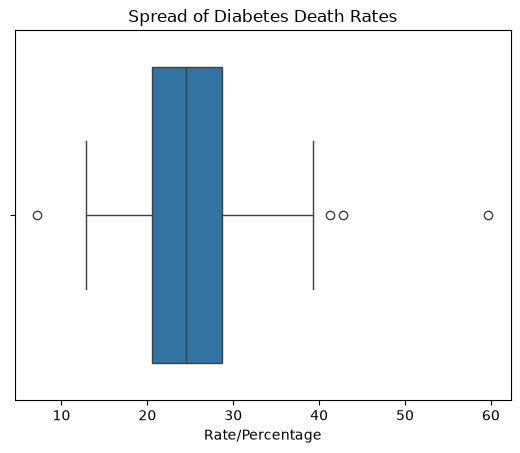

In [47]:
# 2. Box plot
sns.boxplot(x=diabetes["Rate/Percentage"])
plt.title("Spread of Diabetes Death Rates")
plt.show()

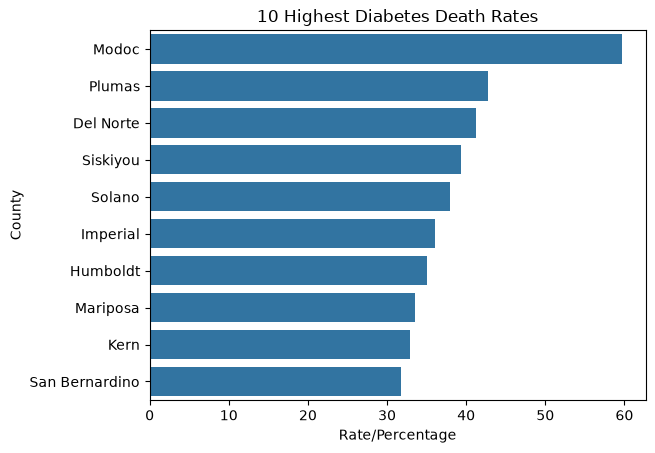

In [48]:
# 3. Highest 10 counties
top10 = diabetes.nlargest(10, "Rate/Percentage")
sns.barplot(data=top10, x="Rate/Percentage", y="County")
plt.title("10 Highest Diabetes Death Rates")
plt.show()

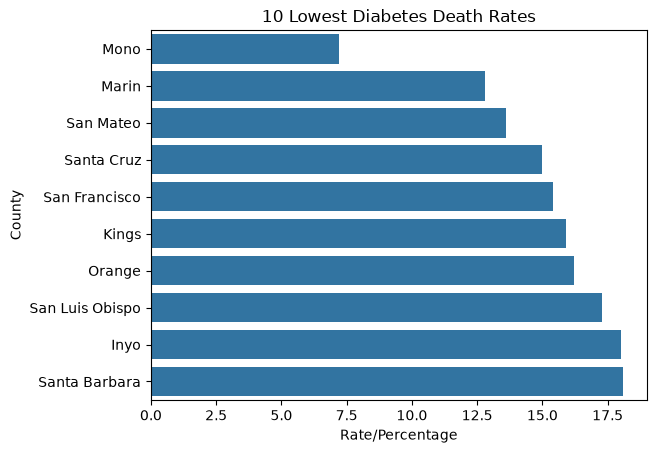

In [49]:
# 4. Lowest 10 counties
bottom10 = diabetes.nsmallest(10, "Rate/Percentage")
sns.barplot(data=bottom10, x="Rate/Percentage", y="County")
plt.title("10 Lowest Diabetes Death Rates")
plt.show()

#### Comparing Health Measures and Population Groups

The scatter plot compares crude and age-adjusted all-cause death rates. The histograms show the reported gonorrhea incidence rates for females and males aged 15–44. These charts describe the data and do not show what caused the differences.

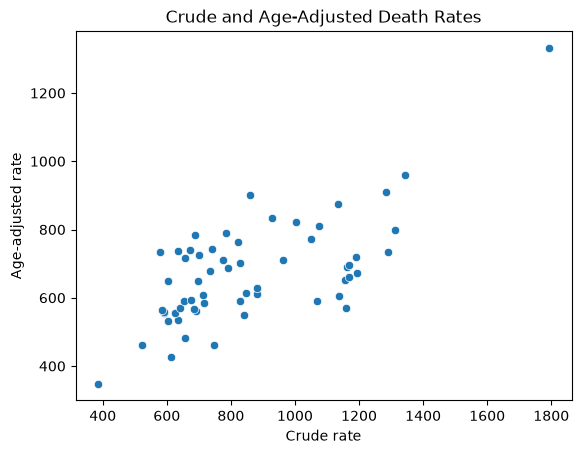

In [54]:
# 5. Crude vs. age-adjusted all-cause death rates
all_causes = cdata[cdata["Health_Indicator_Desc"] == "Deaths Due to All Causes"]
sns.scatterplot(data=all_causes, x="Rate/Percentage", y="Age-Adjusted_Rate")
plt.title("Crude and Age-Adjusted Death Rates")
plt.xlabel("Crude rate")
plt.ylabel("Age-adjusted rate")
plt.show()

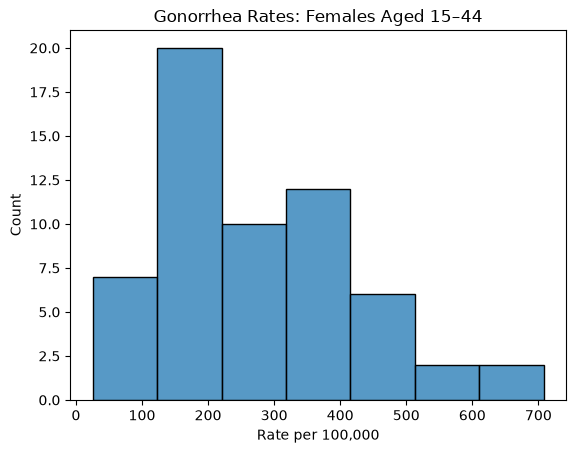

In [55]:
# 6. Female gonorrhea incidence rates
female = cdata[cdata["Health_Indicator_Desc"] ==
              "Reported Incidence of Gonorrhea among Females 15 to 44 Years Old"]
sns.histplot(female["Rate/Percentage"].dropna())
plt.title("Gonorrhea Rates: Females Aged 15–44")
plt.xlabel("Rate per 100,000")
plt.show()

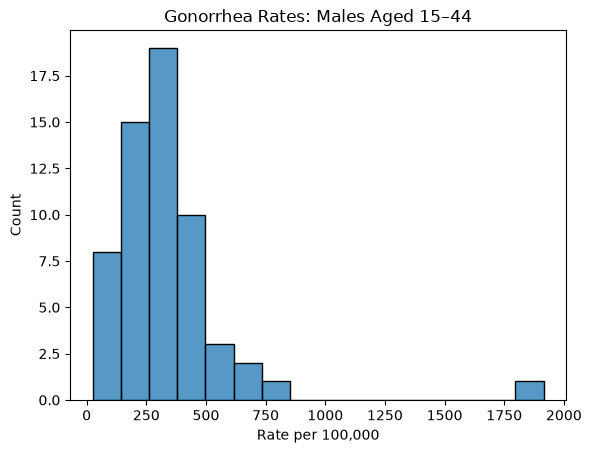

In [56]:
# 7. Male gonorrhea incidence rates
male = cdata[cdata["Health_Indicator_Desc"] ==
            "Reported Incidence of Gonorrhea among Males 15 to 44 Years Old"]
sns.histplot(male["Rate/Percentage"].dropna())
plt.title("Gonorrhea Rates: Males Aged 15–44")
plt.xlabel("Rate per 100,000")
plt.show()

#### County Rate Comparison

This chart compares diabetes death rates across counties, ordered from lower to higher. I use it to see how much the reported rates differ between counties.

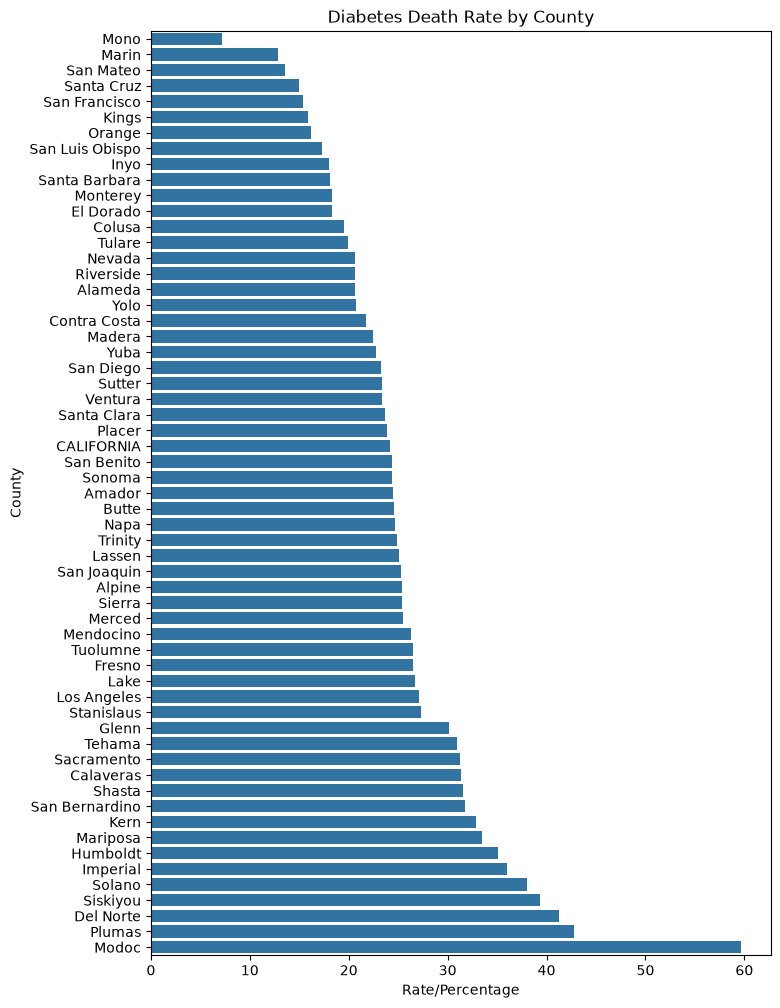

In [57]:
# 8. Diabetes rates by county, sorted
diabetes_sorted = diabetes.sort_values("Rate/Percentage")
plt.figure(figsize=(8, 12))
sns.barplot(data=diabetes_sorted, x="Rate/Percentage", y="County")
plt.title("Diabetes Death Rate by County")
plt.show()

#### Healthy People Objective Status

The final charts summarize whether Healthy People objectives were marked as met or not met. Missing statuses are shown separately or excluded from the group comparison; they are not counted as “not met.”

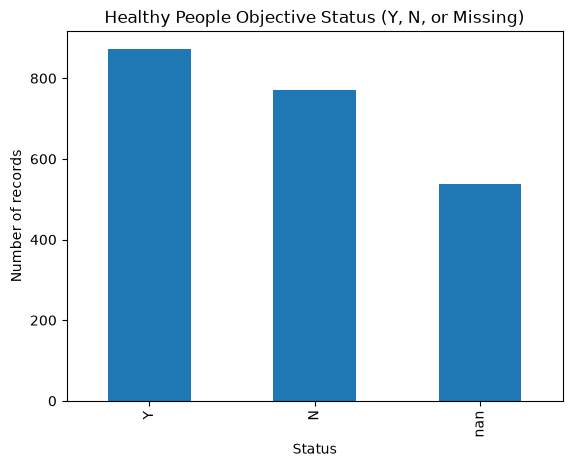

In [59]:
# 9. Healthy People objective status counts
cdata["Healthy_People_Objective_Met"].value_counts(dropna=False).plot(kind="bar")
plt.title("Healthy People Objective Status (Y, N, or Missing)")
plt.xlabel("Status")
plt.ylabel("Number of records")
plt.show()


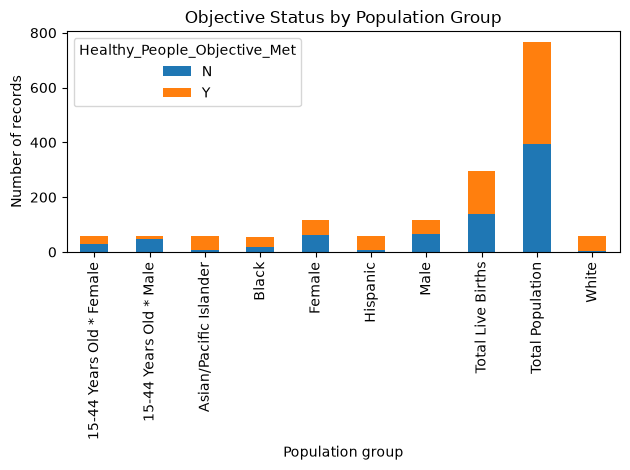

In [61]:
# 10. Objective status by population group
pd.crosstab(
    cdata["Strata_Name"],
    cdata["Healthy_People_Objective_Met"]
).plot(kind="bar", stacked=True)
plt.title("Objective Status by Population Group")
plt.xlabel("Population group")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

#### Key Findings

1. The diabetes death rates across counties were lowest in Mono and highest in Modoc.
2. The top 5 counties with the highest reported diabetes death rates were Modoc, Plumas, Del Norte, Siskiyou and Solano .
3. The top counties with the lowest reported diabetes death rates were Mono, Marin, San Mateo, Santa Cruz, San Francisco.
4. The average reported gonorrhea incidence rate was higher for males aged 15–44 (357.3 per 100,000) than for females aged 15–44 (293.6). Among the 54    counties with rates for both groups, the male rate was higher in 35 counties and the female rate was higher in 19.
5. All-cause crude and age-adjusted death rates showed a positive relationship across counties (correlation about 0.68). Alpine County had the highest    age-adjusted rate (1,332.8 per 100,000), while Mono County had the lowest (348.3).


#### Conclusion

This analysis compared selected health rates across counties and reviewed reported Healthy People objective statuses. Some rates and objective statuses are unavailable, so the findings apply only to the records with reported values. The charts show associations and differences, not cause and effect.